# MetPipe: what made it into the database?

Twenty stations and twenty years of files are not the same as twenty complete observation records. This notebook checks the finalized, observed-only layer by station, year and element. It reads committed audit summaries, not the live database.

Scope: **2005–2024, UTC, 20 stations, 3,506,400 expected station-hours**. Missing hours are included in the denominator. No reconstruction is counted.

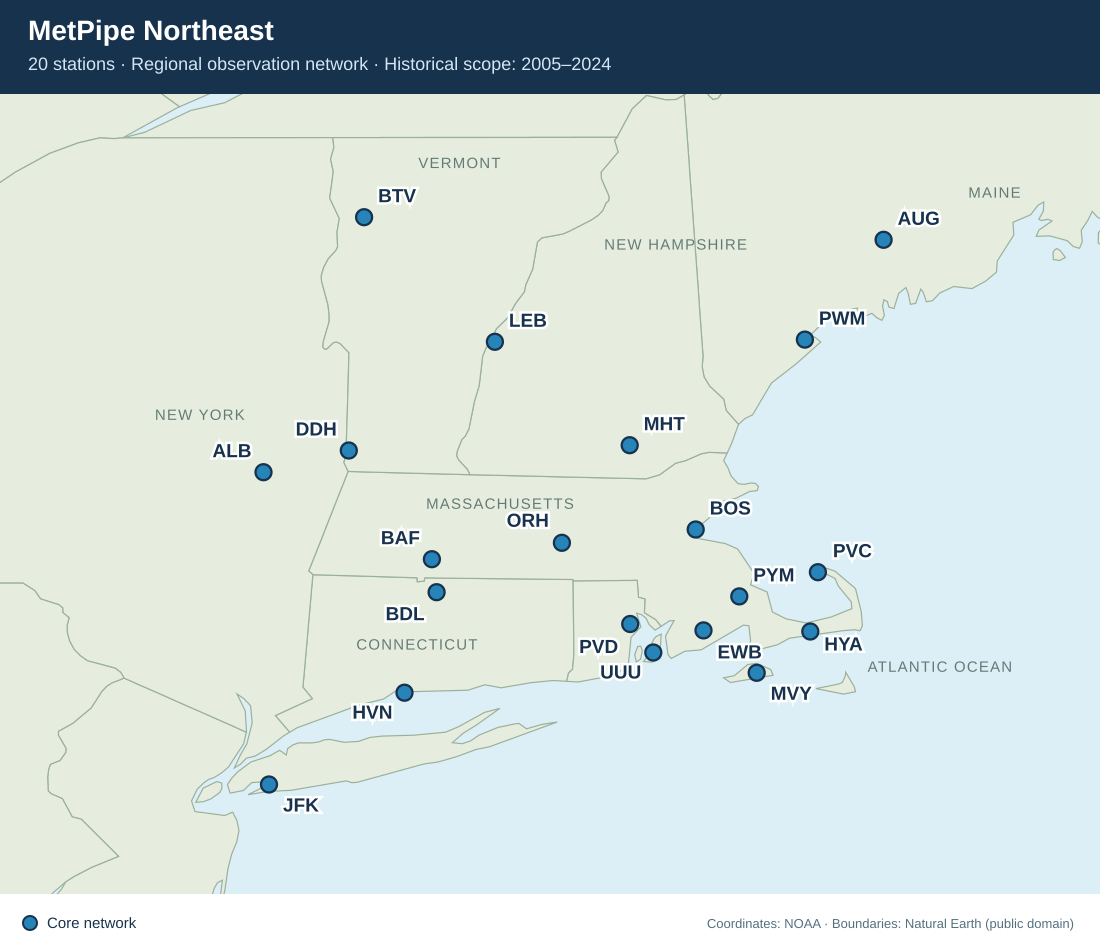

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, SVG
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'reports/data_availability.csv').is_file())
stations=pd.read_csv(ROOT/'reports/data_availability.csv').set_index('station').sort_index()
years=pd.read_csv(ROOT/'reports/station_year_availability.csv')
assert len(stations)==20 and len(years)==400
assert stations.expected_hours.sum()==3506400
display(SVG(filename=str(ROOT/'docs/assets/station_network.svg')))

## Coverage varies by element

The table and chart count accepted finalized observations. Availability is not an independent accuracy score. Gust presence is conditional, and missing precipitation must not be interpreted as dry weather.

,Temperature (%),Dew point (%),RH (%),Station pressure (%),Wind speed (%)
station,,,,,
ALB,99.98,99.98,99.99,99.90,99.99
AUG,99.81,99.79,99.79,99.84,99.70
BAF,99.33,99.31,99.31,99.52,99.65
BDL,99.95,99.95,99.95,99.68,99.96
BOS,99.98,99.97,99.98,99.83,99.98
BTV,99.94,99.89,99.90,99.61,99.89
DDH,99.22,98.85,98.85,99.61,99.07
EWB,99.25,99.05,99.04,99.53,99.67
HVN,99.34,99.34,99.33,99.46,99.71


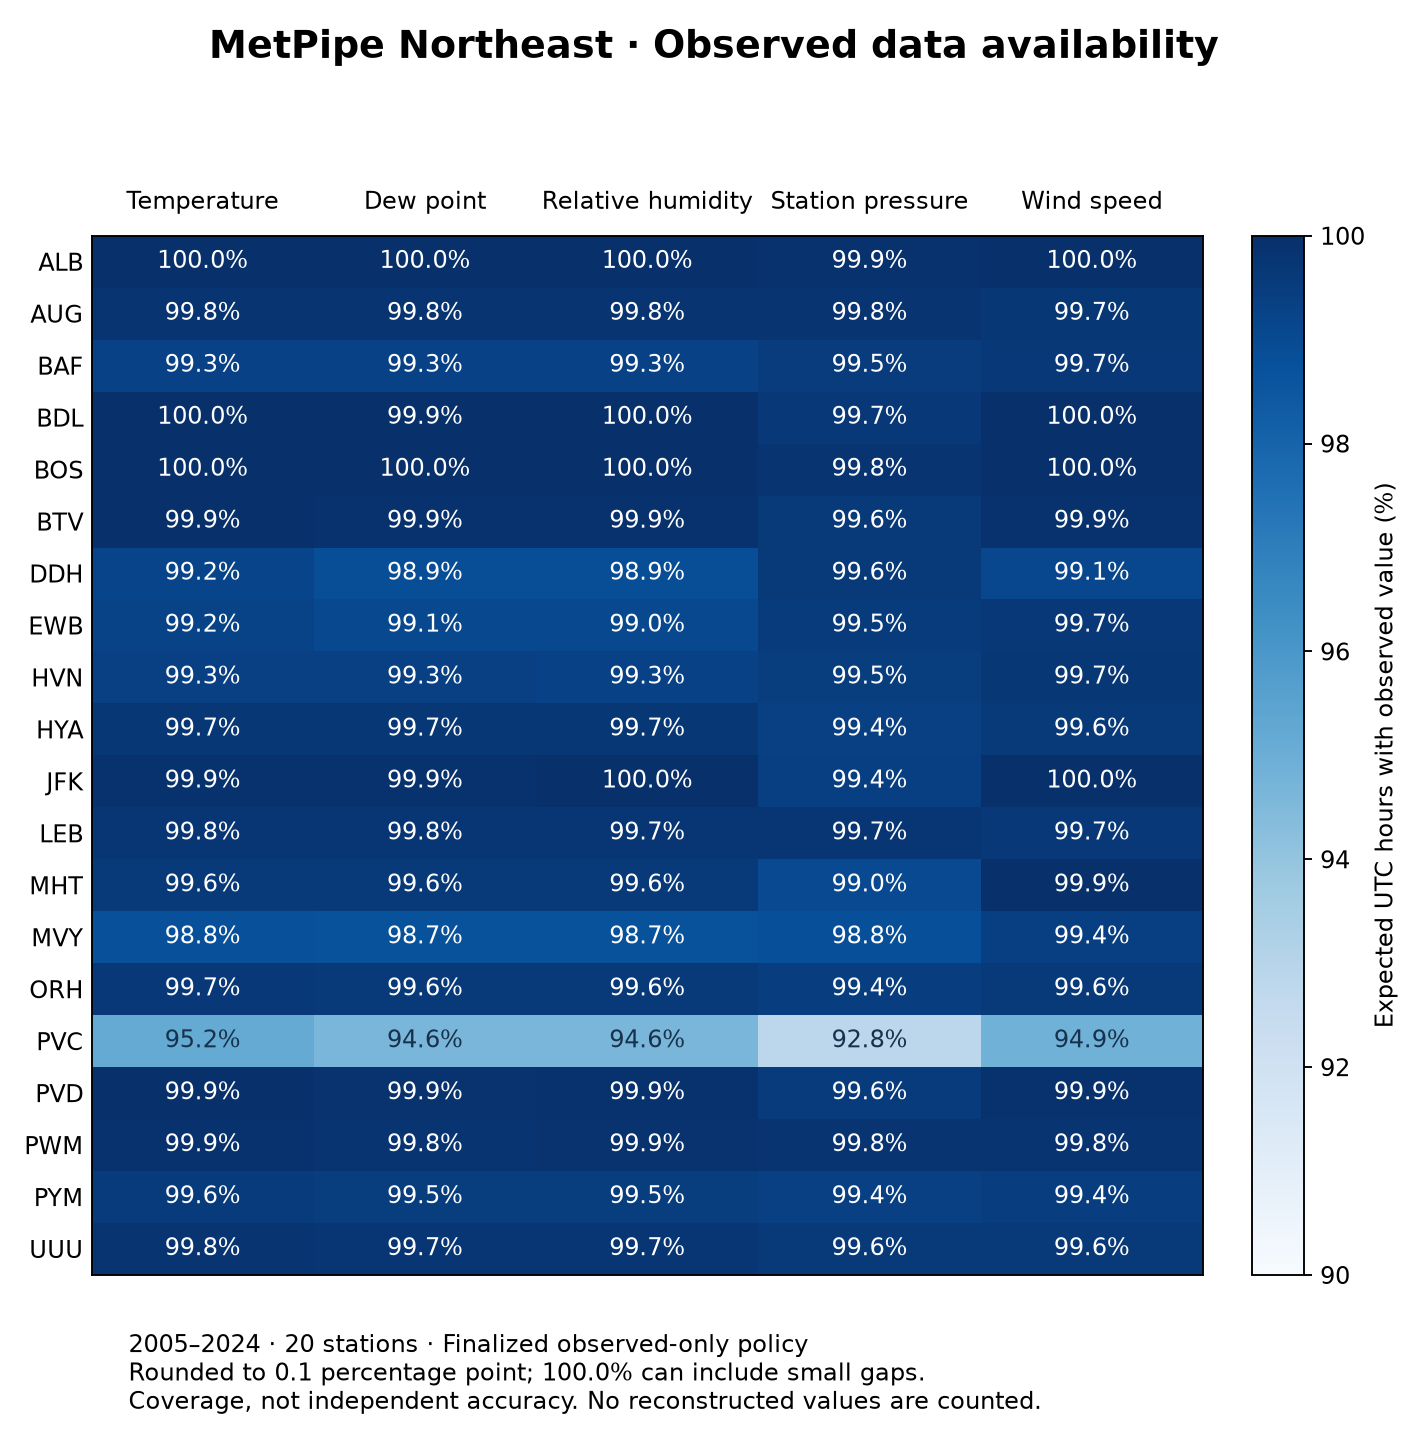

In [2]:
columns={'temperature_c_pct':'Temperature (%)','dewpoint_c_pct':'Dew point (%)','relative_humidity_pct':'RH (%)','station_pressure_hpa_pct':'Station pressure (%)','wind_speed_ms_pct':'Wind speed (%)'}
display(stations[list(columns)].rename(columns=columns).round(2))
display(Image(filename=str(ROOT/'docs/assets/data_availability.png'),width=760))

## An aggregate can hide a long outage

PVC has 92.79% observed station-pressure coverage overall, but only 61.75% in 2006. A later modeling project can address supported gaps; the ETL layer should first make them visible and preserve what was actually observed.

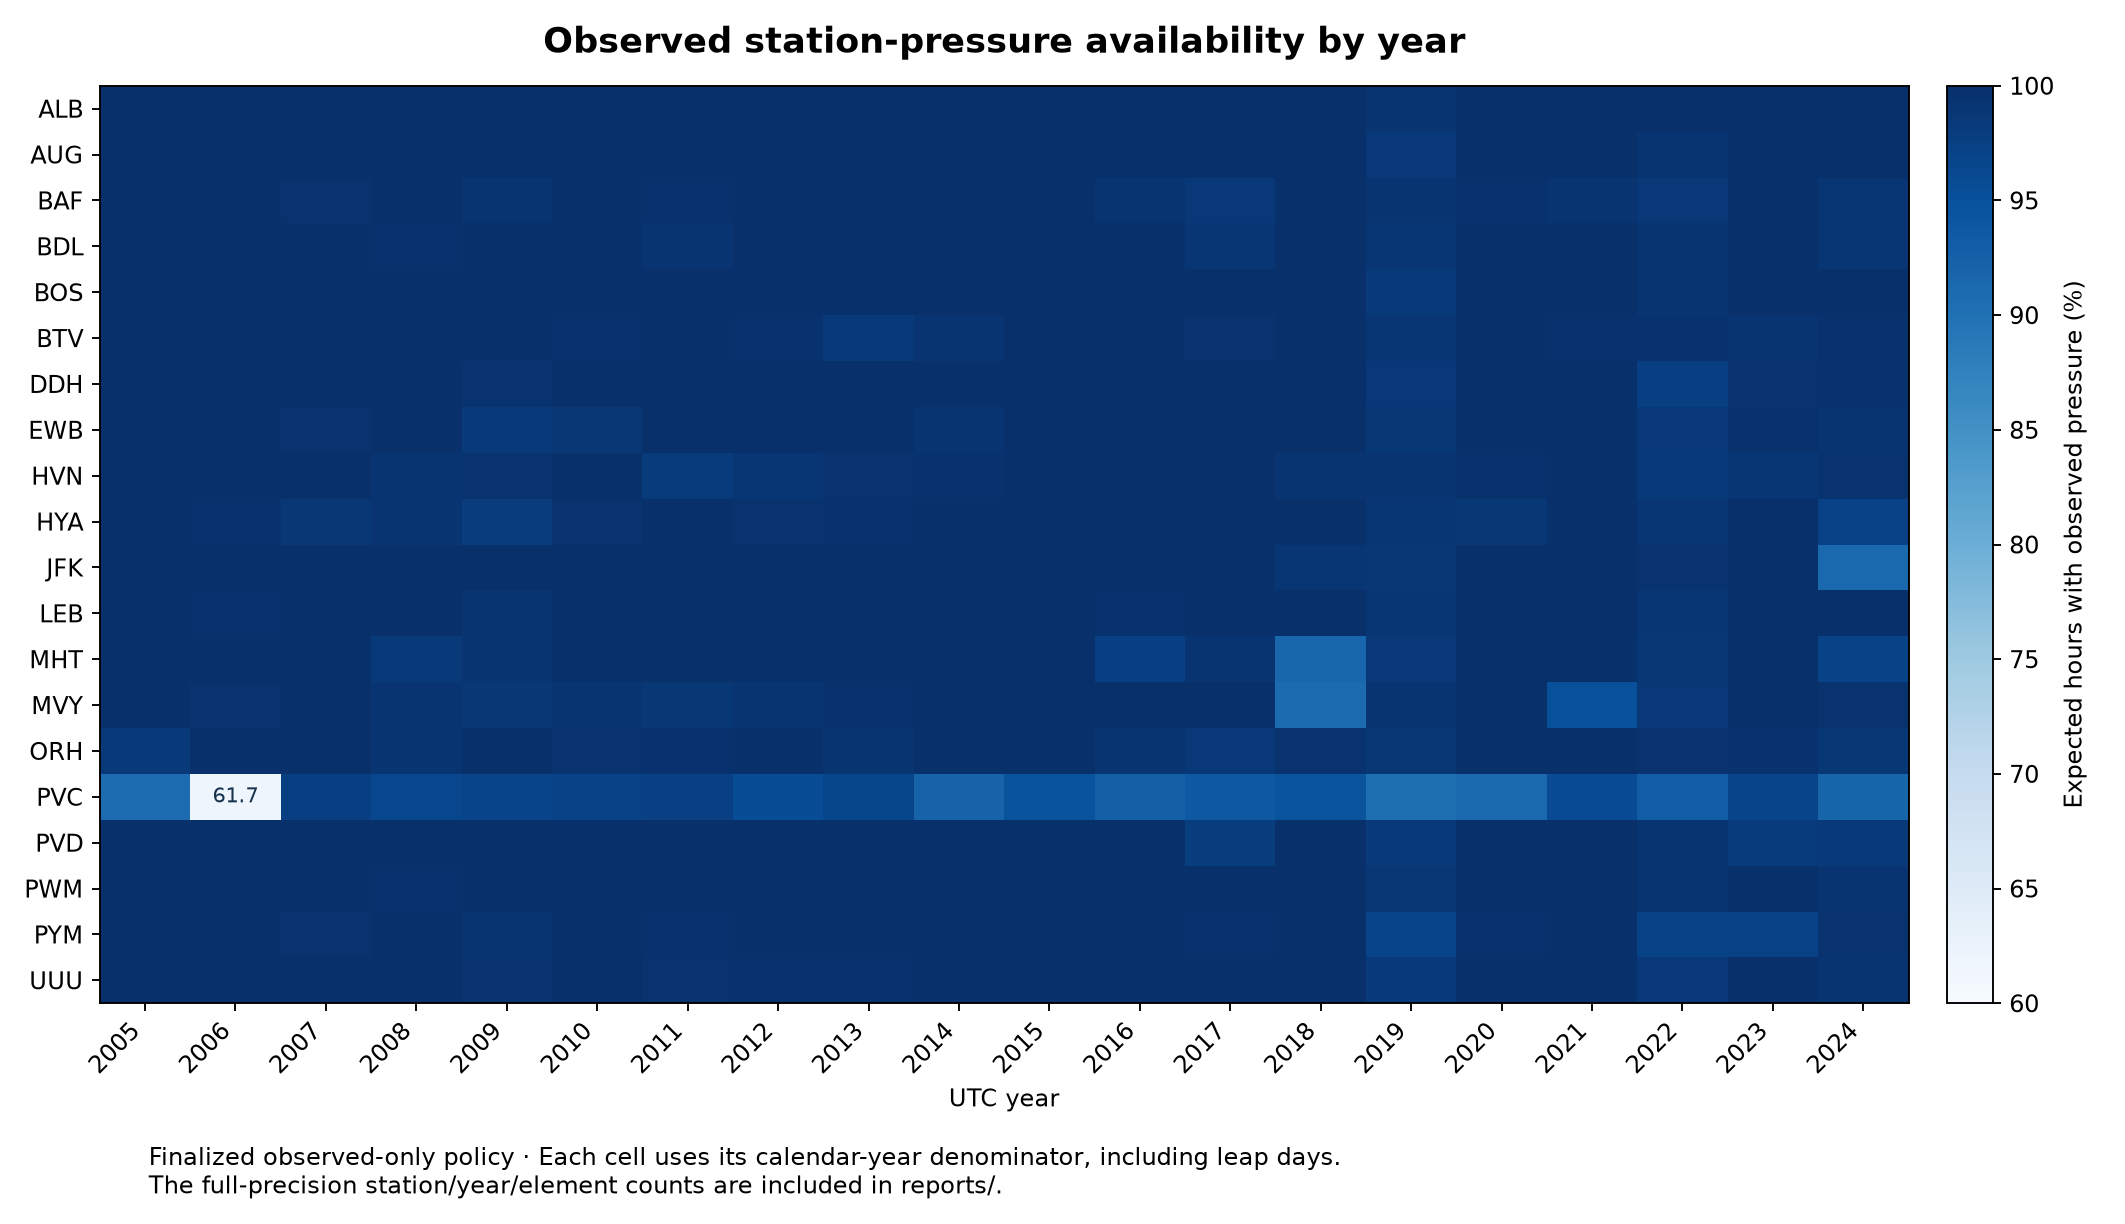

,station,year,expected_hours,station_pressure_hpa_hours,station_pressure_hpa_pct
301,PVC,2006,8760,5409,61.75
314,PVC,2019,8760,7923,90.45
300,PVC,2005,8760,7942,90.66
273,MVY,2018,8760,7959,90.86
315,PVC,2020,8784,8004,91.12
219,JFK,2024,8784,8029,91.40
253,MHT,2018,8760,8021,91.56
319,PVC,2024,8784,8062,91.78


In [3]:
display(Image(filename=str(ROOT/'docs/assets/pressure_availability_by_year.png'),width=1100))
display(years.sort_values('station_pressure_hpa_pct').head(8)[['station','year','expected_hours','station_pressure_hpa_hours','station_pressure_hpa_pct']].round(2))
assert not years.duplicated(['station','year']).any()

## The output contract

`metpipe_final.weather_hourly_utc` supplies a complete UTC hourly calendar with SI fields and per-element source/timestamp provenance. A source disagreement leaves only the unresolved element blank. Raw archives remain available; estimated values belong to a different layer and project.

The summaries are from `observed_2005_2024_v1`, audited October 14, 2026. Full counts and export hashes are in `reports/`. See the pipeline guide for ingestion and publication commands. This notebook makes no database changes.